In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn

First some Conceptual Clarity through Demonstrations.

In [ ]:
rng = np.random.RandomState(1)
X = np.sort(5 * rng.rand(80, 1), axis=0)
y = np.sin(X).ravel()
y[::5] += 3 * (0.5 - rng.rand(16))

In [ ]:
from sklearn.tree import DecisionTreeRegressor

regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_1.fit(X, y)
regr_2.fit(X, y)

DecisionTreeRegressor(max_depth=5)

In [ ]:
X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)

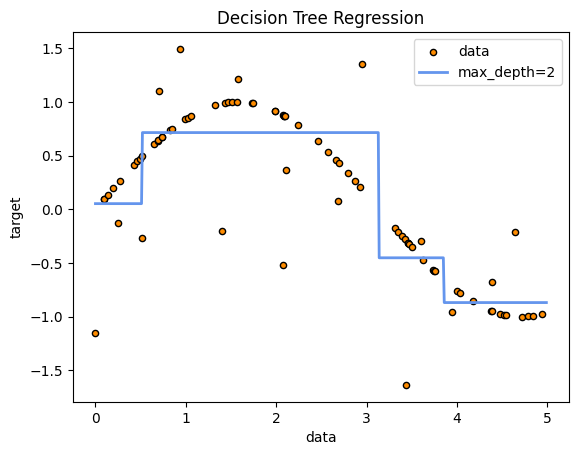

In [ ]:
plt.figure()
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test, y_1, color="cornflowerblue", label="max_depth=2", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

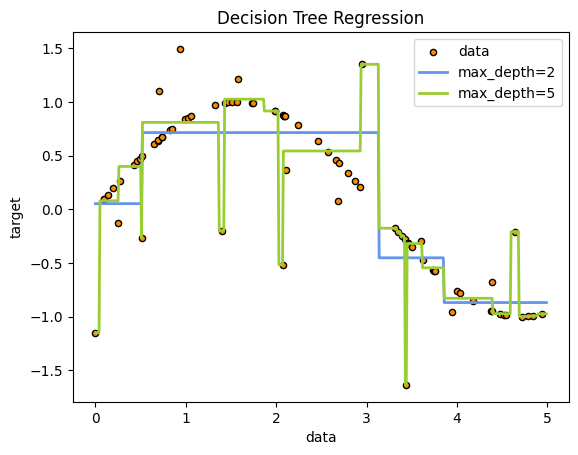

In [ ]:
plt.figure()
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test, y_1, color="cornflowerblue", label="max_depth=2", linewidth=2)
plt.plot(X_test, y_2, color="yellowgreen", label="max_depth=5", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

In [ ]:
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from patsy import dmatrices
from sklearn.model_selection import cross_val_score, KFold
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelBinarizer

In [ ]:
file_path = "/content/Student_Performance.csv"

df = pd.read_csv(file_path)

print("First 5 records:", df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/Student_Performance.csv'

In [ ]:
x = df.drop(columns='Performance Index')
y = df["Performance Index"]

In [ ]:
lb = LabelBinarizer()
df['Encoded_Activities'] = lb.fit_transform(df['Extracurricular Activities'])
df = df.drop(columns='Extracurricular Activities')
df.sample()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Performance Index,Encoded_Activities
8486,9,53,9,6,51.0,0


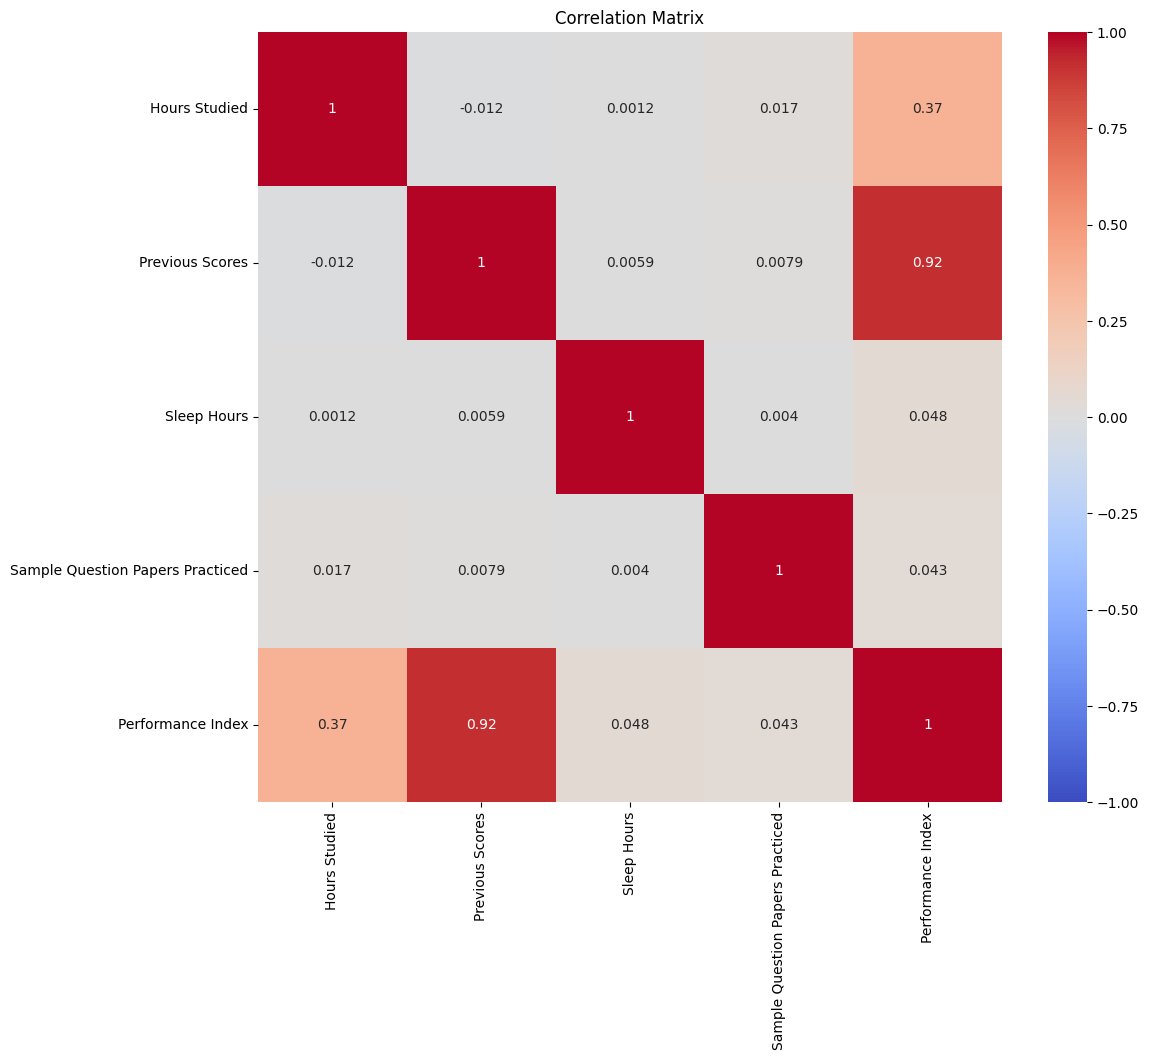

In [ ]:
correlation = pd.concat([x, y], axis=1).corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(correlation, vmin=-1, vmax=1, center=0, ax=ax, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

Model with Intercept Only

In [ ]:
model = smf.ols(formula='y ~ 1', data=df).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                      -0.000
Model:                            OLS   Adj. R-squared:                 -0.000
Method:                 Least Squares   F-statistic:                       nan
Date:                Thu, 14 May 2026   Prob (F-statistic):                nan
Time:                        03:04:34   Log-Likelihood:                -43745.
No. Observations:               10000   AIC:                         8.749e+04
Df Residuals:                    9999   BIC:                         8.750e+04
Df Model:                           0                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     55.2248      0.192    287.441      0.0

Model with 1 Feature

In [ ]:
formula_1 = 'y ~ Q("Hours Studied")'

model_1 = smf.ols(formula=formula_1, data=df).fit()

print(model_1.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.140
Model:                            OLS   Adj. R-squared:                  0.140
Method:                 Least Squares   F-statistic:                     1623.
Date:                Thu, 14 May 2026   Prob (F-statistic):               0.00
Time:                        03:04:41   Log-Likelihood:                -42992.
No. Observations:               10000   AIC:                         8.599e+04
Df Residuals:                    9998   BIC:                         8.600e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                         coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept             41.3792      0

In [ ]:
formula_2 = 'y ~ Q("Hours Studied") + Q("Previous Scores")'

model_2 = smf.ols(formula=formula_2, data=df).fit()

print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.986
Model:                            OLS   Adj. R-squared:                  0.986
Method:                 Least Squares   F-statistic:                 3.488e+05
Date:                Thu, 14 May 2026   Prob (F-statistic):               0.00
Time:                        03:05:19   Log-Likelihood:                -22446.
No. Observations:               10000   AIC:                         4.490e+04
Df Residuals:                    9997   BIC:                         4.492e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -29.8168 

Model with Combined Features

In [ ]:
formula_3 = 'y ~ Q("Hours Studied") + Q("Previous Scores") + Q("Sleep Hours") * Encoded_Activities'

model_3 = smf.ols(formula=formula_3, data=df).fit()

print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.988
Model:                            OLS   Adj. R-squared:                  0.988
Method:                 Least Squares   F-statistic:                 1.634e+05
Date:                Thu, 14 May 2026   Prob (F-statistic):               0.00
Time:                        03:06:56   Log-Likelihood:                -21665.
No. Observations:               10000   AIC:                         4.334e+04
Df Residuals:                    9994   BIC:                         4.339e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                          coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------
In

# Cross Validation
Using 5-fold CV to evaluate model stability and comparing RMSE across all four model iterations to ensure results aren't due to luck.

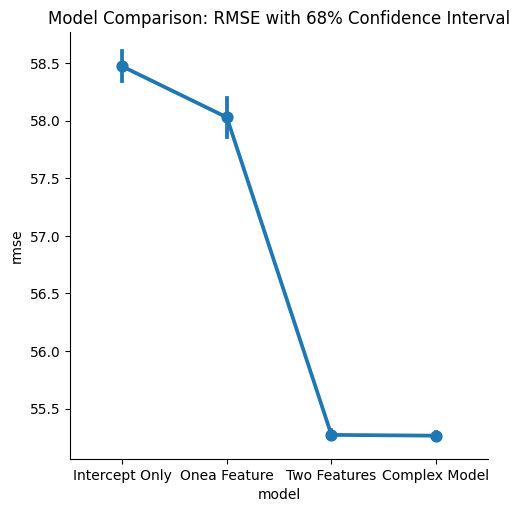

In [ ]:
formulas = [
    'y ~ 1',
    'y ~ Q("Hours Studied")',
    'y ~ Q("Hours Studied") + Q("Previous Scores")',
    'y ~ Q("Hours Studied") + Q("Previous Scores") + Q("Sleep Hours") * Encoded_Activities'
]
model_names = ['Intercept Only', 'Onea Feature', 'Two Features', 'Complex Model']
cv_results = []
kf = KFold(n_splits=5, shuffle=True, random_state=9)

for formula, name in zip(formulas, model_names):
    y, X = dmatrices(formula, data=df, return_type='dataframe')

    pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression(fit_intercept=False))
    ])

    scores = -cross_val_score(pipeline, X, y.values.ravel(), cv=kf, scoring='neg_root_mean_squared_error')

    fold_results = pd.DataFrame({'model': name, 'rmse': scores})
    cv_results.append(fold_results)

final_df = pd.concat(cv_results, axis=0)

sns.catplot(data=final_df, x='model', y='rmse', kind='point', errorbar=('ci', 68))
plt.title("Model Comparison: RMSE with 68% Confidence Interval")
plt.show()

# Model Selection

We have chosen Model 2 (Multiple Linear Regression with 2 features) as our final model. Although the Complex Model (Model 3) introduced an interaction term and a third variable, the improvement in R2 (from 0.986 to 0.988) and the decrease in RMSE were marginal. Additionally, the interaction term was not statistically significant (p=0.959), making the simpler model more robust and interpretable.

In [ ]:
final_formula = 'y ~ Q("Hours Studied") + Q("Previous Scores")'
final_model = smf.ols(formula=final_formula, data=df).fit()
print(final_model.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.986
Model:                            OLS   Adj. R-squared:                  0.986
Method:                 Least Squares   F-statistic:                 3.488e+05
Date:                Thu, 14 May 2026   Prob (F-statistic):               0.00
Time:                        03:14:19   Log-Likelihood:                -22446.
No. Observations:               10000   AIC:                         4.490e+04
Df Residuals:                    9997   BIC:                         4.492e+04
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
Intercept              -29.8168 

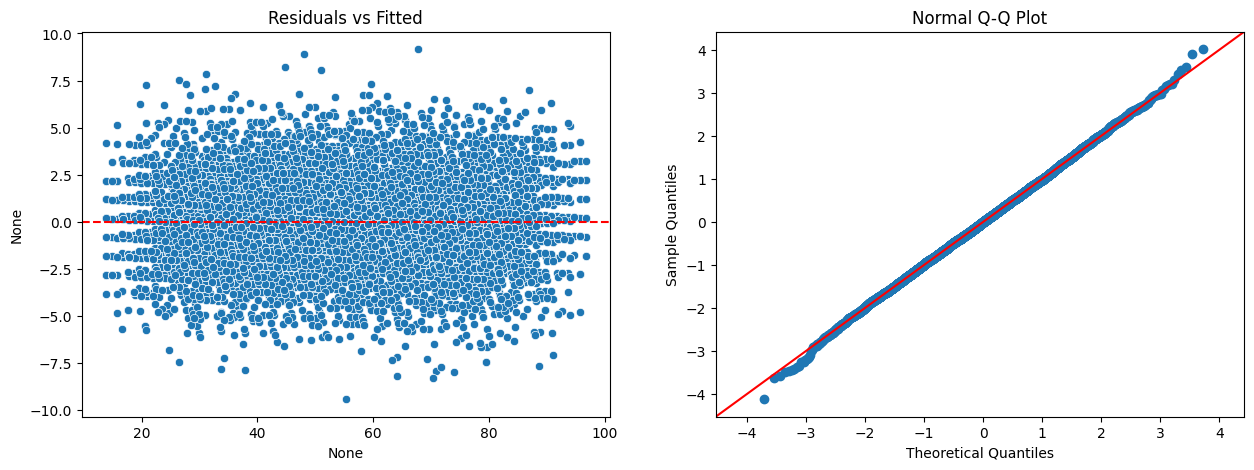

In [ ]:
import statsmodels.api as sm


residuals = final_model.resid
fitted = final_model.fittedvalues


fig, ax = plt.subplots(1, 2, figsize=(15, 5))


sns.scatterplot(x=fitted, y=residuals, ax=ax[0])
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_title('Residuals vs Fitted')


sm.qqplot(residuals, line='45', fit=True, ax=ax[1])
ax[1].set_title('Normal Q-Q Plot')

plt.show()

Our final model explains 98.8% of the variance in student performance. While Previous Scores is the strongest predictor, we found that Hours Studied provides a significant, consistent boost. Interestingly, the interaction between sleep and activities was not significant (p=0.959), suggesting that the benefit of sleep is universal regardless of a student's schedule.

In [ ]:
from sklearn.model_selection import train_test_split
x = df.drop(columns='Performance Index')
y = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(x, y, test_size=0.33, random_state=42)

regr = DecisionTreeRegressor()
regr.fit(X_train, y_train)

DecisionTreeRegressor()

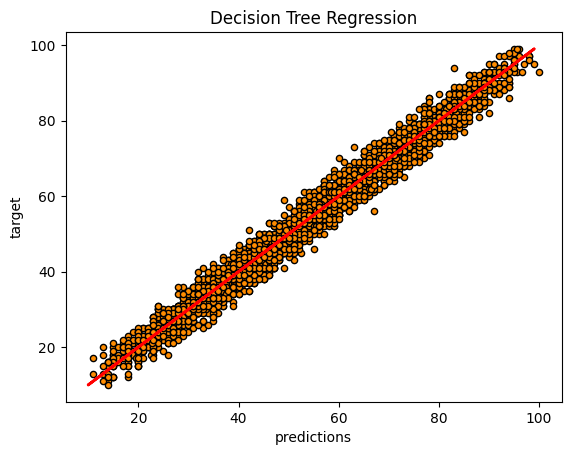

In [ ]:
y_1 = regr.predict(X_test)
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(y_1, y_test, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(y_test, y_test, color="red", linewidth=2)
plt.xlabel("predictions")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.show()

In [ ]:
x

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Encoded_Activities
0,7,99,9,1,1
1,4,82,4,2,0
2,8,51,7,2,1
3,5,52,5,2,1
4,7,75,8,5,0
...,...,...,...,...,...
9995,1,49,4,2,1
9996,7,64,8,5,1
9997,6,83,8,5,1
9998,9,97,7,0,1


Taking only the two features from Model-2

In [ ]:
x_0 = df[["Hours Studied", "Previous Scores"]]
y_0 = df["Performance Index"]

X_train, X_test, y_train, y_test = train_test_split(x_0, y_0, test_size=0.33, random_state=42)

regr = DecisionTreeRegressor()
regr.fit(X_train, y_train)

DecisionTreeRegressor()

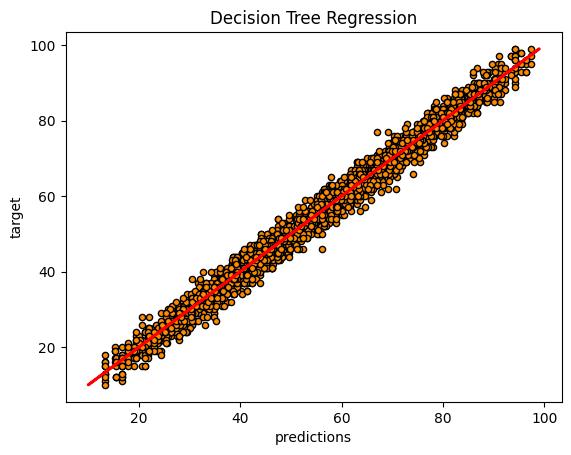

In [ ]:
y_1 = regr.predict(X_test)
import matplotlib.pyplot as plt

plt.figure()
plt.scatter(y_1, y_test, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(y_test, y_test, color="red", linewidth=2)
plt.xlabel("predictions")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.show()